**PRACTICA 5**

Integrantes:
   

  
   - Paula García
   - Valentina Morales

   ---

**Parte guiada**

Se parte de la señal analógica $x_a(t) = A\sin(2\pi F_0 t)$ con $F_0 = 40$ Hz y $A = 5$ V, muestreada a $F_s = 1000$ Hz.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

Fo = 40            
Tp = 1/Fo          
Fs = 1000          
T = 1/Fs           
A = 5              

t = np.arange(0, Tp+T, T)        
x = A*np.sin(2*np.pi*Fo*t)       

fo = Fo/Fs                       # frecuencia discreta: 0.04
n = np.arange(0, len(t))         
x1 = A*np.sin(2*np.pi*fo*n)      

a) Compruebe que los valores de las primeras cinco muestras son los mismos

In [ ]:
print(x[:5])
print(x1[:5])
print(np.allclose(x, x1))   # True si todas las muestras coinciden

[0.         1.24344944 2.40876837 3.42273553 4.22163963]
[0.         1.24344944 2.40876837 3.42273553 4.22163963]
True


**Respuesta.** Las primeras cinco muestras de $x(t)$ y $x_1(n)$ son iguales (0, 1.2434, 2.4088, 3.4227 y 4.2216 V). Esto pasa porque $t = nT$, entonces $2\pi F_0 t = 2\pi (F_0/F_s) n$. Es la misma señal, solo cambia el eje: segundos en una y número de muestra en la otra.


---

b) La potencia es la misma que en x(n). ¿Por qué?

Se calcula la energía, la potencia media y el valor RMS de un ciclo, y luego de 10 ciclos.

In [3]:
# Un ciclo
energia = sum(x**2)
potencia = energia/(len(t)-1)
rms = np.sqrt(potencia)

# Diez ciclos (250 ms)
t10 = np.arange(0, 10*Tp+T, T)
x10 = A*np.sin(2*np.pi*Fo*t10)
energia10 = sum(x10**2)
potencia10 = energia10/(len(t10)-1)
rms10 = np.sqrt(potencia10)

print("1 ciclo:   E =", energia, " P =", potencia, " RMS =", rms)
print("10 ciclos: E =", energia10, " P =", potencia10, " RMS =", rms10)

1 ciclo:   E = 312.50000000000006  P = 12.500000000000002  RMS = 3.5355339059327378
10 ciclos: E = 3125.0000000000014  P = 12.500000000000005  RMS = 3.535533905932738


**Respuesta.** Con un ciclo la energía es 312.5 V²·s y con 10 ciclos es 3125 V²·s, pero la potencia es 12.5 W en los dos casos (RMS = 3.54 V). La potencia es la energía promediada en el tiempo: con 10 ciclos la energía se multiplica por 10, pero también se divide entre 10 veces más muestras. Como la señal es periódica, cada ciclo aporta lo mismo. El resultado coincide con el valor teórico $A^2/2 = 12.5$ W.

---

**Aplicación**

**1. Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, y utilice la frecuencia de muestreo necesaria para representarla apropiadamente.**

Fs mínima teórica: mayor que 320 Hz
Muestras: 250  Duración: 0.25 s


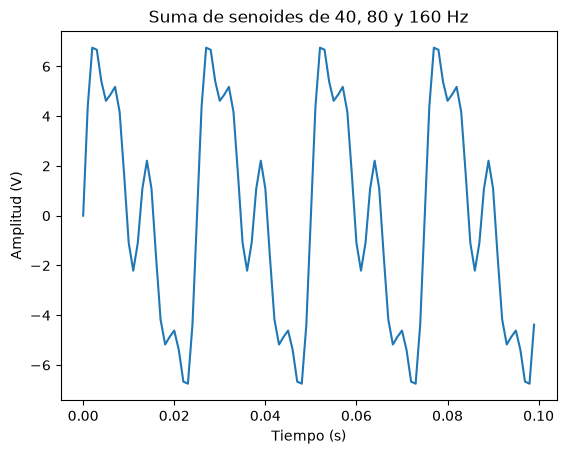

In [ ]:
F = [40, 80, 160]   
A = [5, 3, 2]          

Fmax = max(F)          # frecuencia más alta: 160 Hz
Fs_min = 2*Fmax        # 320 Hz: Fs debe ser MAYOR que este valor (Nyquist)
print("Fs mínima teórica: mayor que", Fs_min, "Hz")

Fs = 1000              # frecuencia de muestreo elegida (Hz)
T = 1/Fs
Tp = 1/40              
t = np.arange(0, 10*Tp, T)    # 10 periodos: 0.25 s, 250 muestras

x = sum(a*np.sin(2*np.pi*f*t) for a, f in zip(A, F))   # suma de las tres senoides
print("Muestras:", len(t), " Duración:", len(t)*T, "s")

plt.plot(t[:100], x[:100])     
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (V)")
plt.title("Suma de senoides de 40, 80 y 160 Hz")
plt.show()

**Respuesta.** La componente de mayor frecuencia es de 160 Hz. Por el criterio de Nyquist, la frecuencia de muestreo debe ser mayor que el doble de esa frecuencia: $F_s > 2 \cdot 160 = 320$ Hz. Se usó $F_s = 1000$ Hz, que cumple el criterio y deja unas 6 muestras por ciclo del componente de 160 Hz, suficiente para ver bien la forma de onda. Se tomaron 10 periodos de la fundamental (0.25 s), es decir, 250 muestras.


---

**2. Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia. Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos de la señal).**

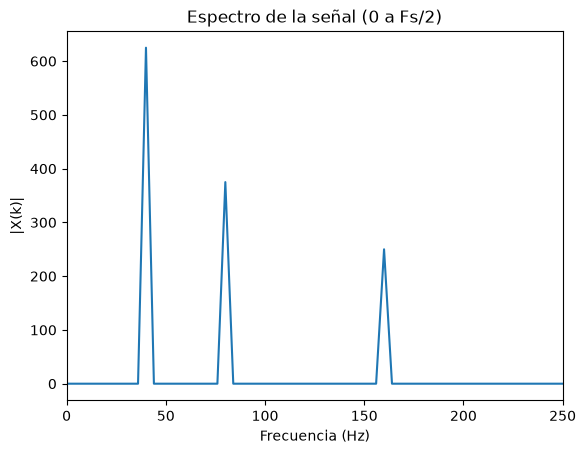

f = 40 Hz | |X| = 625.0 | amplitud = 5.00 V
f = 80 Hz | |X| = 375.0 | amplitud = 3.00 V
f = 160 Hz | |X| = 250.0 | amplitud = 2.00 V


In [5]:
from scipy.signal import find_peaks

X = np.fft.fft(x)                  # DFT de la señal (250 puntos, números complejos)
N = len(X)                         # número de muestras: 250
frec = np.arange(0, N)*Fs/N        # eje de frecuencias: F = k*Fs/N (Hz)

# Solo la primera mitad (hasta Fs/2 = 500 Hz, la frecuencia de Nyquist)
Nmitad = int(np.ceil(N/2))
frec_mitad = frec[:Nmitad]
X_mitad = abs(X[:Nmitad])          # módulo de la DFT

plt.plot(frec_mitad, X_mitad)
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("|X(k)|")
plt.title("Espectro de la señal (0 a Fs/2)")
plt.xlim(0, 250)                   # zoom para ver los picos
plt.show()

# Identificar los picos automáticamente
picos, _ = find_peaks(X_mitad, height=10)
for k in picos:
    print(f"f = {frec_mitad[k]:.0f} Hz | |X| = {X_mitad[k]:.1f} | amplitud = {2*X_mitad[k]/N:.2f} V")

**Respuesta.** En el espectro aparecen tres picos, en 40, 80 y 160 Hz, que son las frecuencias de las componentes de la señal. La resolución en frecuencia es $F_s/N = 1000/250 = 4$ Hz, por eso cada componente cae justo en un punto de la DFT (k = 10, 20 y 40). Como se usaron 10 periodos completos de la señal, no hay fugas de energía: fuera de esos tres picos el espectro es prácticamente cero. El valor del pico es $|X(k)| = N \cdot A/2$, entonces la amplitud se recupera con $A = 2|X(k)|/N$ (5, 3 y 2 V), que coincide con las amplitudes usadas. Solo se grafica hasta $F_s/2 = 500$ Hz porque la otra mitad es simétrica (la señal es real).


---

**3. Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. Aplíquelo a la señal anterior.**

La función de NumPy para calcular la transformada discreta inversa de Fourier es `np.fft.ifft`. Calcula

$$x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k)\, e^{j 2\pi k n / N}$$

es decir, recupera la señal en el tiempo a partir de su DFT (Proakis y Manolakis, 2007).

complex128
1.8731968869366787e-15
3.552713678800501e-15
True


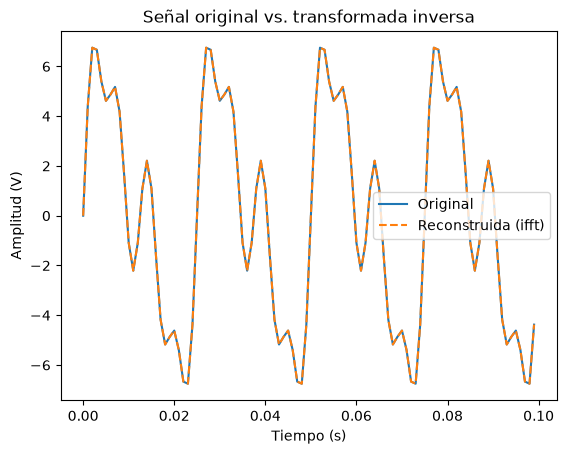

In [6]:
xr = np.fft.ifft(X)       # transformada inversa de la DFT X calculada en el punto 2

print(xr.dtype)                          # complex128: el resultado viene como complejo
print(abs(xr.imag).max())                # parte imaginaria: casi cero (~1e-15)
print(abs(x - xr.real).max())            # error máximo contra la señal original
print(np.allclose(x, xr.real))           # True: la señal se recuperó

plt.plot(t[:100], x[:100], label="Original")
plt.plot(t[:100], xr.real[:100], "--", label="Reconstruida (ifft)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (V)")
plt.title("Señal original vs. transformada inversa")
plt.legend()
plt.show()

**Respuesta.** Al aplicar `np.fft.ifft` a la DFT de la señal se obtiene de vuelta la señal original. El resultado de la función es complejo, pero su parte imaginaria es prácticamente cero (del orden de $10^{-15}$, error numérico del computador), por lo que se toma la parte real con `.real`. El error máximo entre la señal original y la reconstruida es de $3.6 \times 10^{-15}$ V, lo que confirma que la DFT y su inversa son un par de transformadas sin pérdida de información.

---

**4. ¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué?**



C:\Users\PAULA CAMILA\AppData\Local\Temp\ipykernel_24656\77351545.py:3: ComplexWarning: Casting complex values to real discards the imaginary part
  F2[9:13] = F1[9:13]


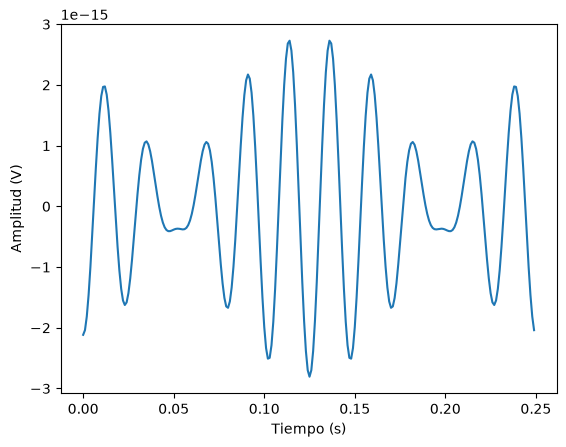

float64 2.8056149108778773e-15


In [7]:
F1 = np.fft.fft(x)
F2 = np.zeros((len(F1)))
F2[9:13] = F1[9:13]
xr = np.fft.ifft(F2)

fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)')
plt.show()

print(F2.dtype, abs(np.real(xr)).max())

**Respuesta.** Sí, las líneas aplican un filtro, pero en el dominio de la frecuencia. Lo que hace cada línea es:

- `F1 = np.fft.fft(x)`: calcula la DFT de la señal, o sea, su espectro.
- `F2 = np.zeros(len(F1))`: crea un espectro vacío, con todos los valores en cero.
- `F2[9:13] = F1[9:13]`: copia solo los coeficientes de los índices 9 a 12 y deja todos los demás en cero. Con $N = 250$ y $F_s = 1000$ Hz, cada índice equivale a $kF_s/N = 4k$ Hz, por lo que esos índices corresponden a 36, 40, 44 y 48 Hz.
- `xr = np.fft.ifft(F2)`: pasa de nuevo al tiempo con el espectro recortado.

Es un filtro porque deja pasar unas frecuencias (las cercanas a 40 Hz) y elimina las demás (en este caso, los componentes de 80 y 160 Hz). Más exactamente es un filtro pasa-banda ideal, ya que corta de forma abrupta, sin zona de transición.

--- 

**Extraiga de manera similar cada una de las componentes de la señal.**

Para que el filtro funcione, el arreglo debe ser complejo (`dtype=complex`). Se repite el procedimiento conservando los mismos índices (9 a 12):

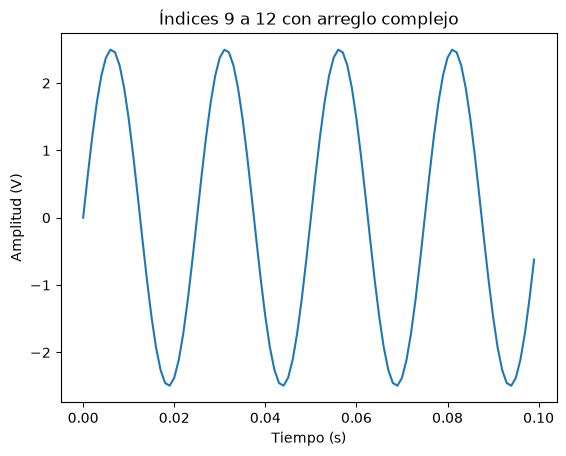

2.4950668210706817


In [8]:
F2c = np.zeros(len(F1), dtype=complex)    # arreglo complejo, ahora no se pierde la parte imaginaria
F2c[9:13] = F1[9:13]
xr_c = np.fft.ifft(F2c)

plt.plot(t[:100], np.real(xr_c[:100]))
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (V)")
plt.title("Índices 9 a 12 con arreglo complejo")
plt.show()
print(abs(np.real(xr_c)).max())           # ≈ 2.5

Con el arreglo complejo se obtiene una senoide de 40 Hz, pero con amplitud de 2.5 V en lugar de 5 V. Esto ocurre porque el espectro de una señal real es simétrico: la mitad de la amplitud está en la frecuencia positiva (índice $k$) y la otra mitad en su simétrica negativa (índice $N-k$). El código solo conserva el lado positivo, por lo que se recupera la mitad de la señal.

40 Hz | k = 10 | error máx = 2.9000972272962627e-14
80 Hz | k = 20 | error máx = 3.5074015138087033e-14
160 Hz | k = 40 | error máx = 5.2735593669694936e-14


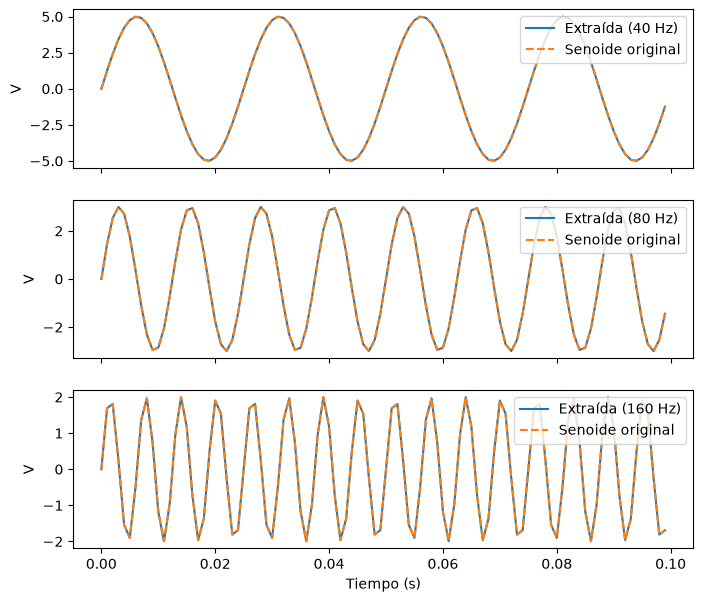

In [9]:
def extraer_componente(F1, k):
    # Deja solo el índice k y su simétrico N-k; el resto se pone en cero
    N = len(F1)
    G = np.zeros(N, dtype=complex)
    G[k] = F1[k]
    G[N-k] = F1[N-k]
    return np.real(np.fft.ifft(G))

N = len(x)
fig, ax = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for a, f, amp in zip(ax, [40, 80, 160], [5, 3, 2]):
    k = int(round(f*N/Fs))                     # índice de cada frecuencia: 10, 20 y 40
    comp = extraer_componente(F1, k)
    a.plot(t[:100], comp[:100], label=f"Extraída ({f} Hz)")
    a.plot(t[:100], amp*np.sin(2*np.pi*f*t[:100]), "--", label="Senoide original")
    a.set_ylabel("V")
    a.legend(loc="upper right")
    print(f, "Hz | k =", k, "| error máx =", abs(comp - amp*np.sin(2*np.pi*f*t)).max())
ax[-1].set_xlabel("Tiempo (s)")
plt.show()

Para extraer cada componente se conserva únicamente su coeficiente $k = fN/F_s$ (10, 20 y 40 para 40, 80 y 160 Hz) junto con su simétrico $N-k$, y se aplica la transformada inversa. Con esto se recuperan las tres senoides originales, de 5, 3 y 2 V, con un error del orden de $10^{-14}$ V. Al sumar las tres componentes se reconstruye la señal original.

---

**5. Cree una función que calcule manualmente el periodograma de Welch de una señal discreta (usando la DFT), explique paso a paso el algoritmo. Pruébelo en una de las señales construidas anteriormente.**

**Algoritmo.** El periodograma de Welch estima la densidad espectral de potencia (PSD) de una señal promediando varios periodogramas calculados en segmentos que se solapan:

1. Se divide la señal de $N$ muestras en $K$ segmentos de longitud $L$ (`nperseg`), con un solapamiento de `noverlap` muestras. El paso entre segmentos es $L - \text{noverlap}$ y $K = \lfloor (N - \text{noverlap}) / (L - \text{noverlap}) \rfloor$.
2. A cada segmento se le resta su media.
3. Se multiplica por una ventana $w(n)$ (aquí Hanning, $w(n) = 0.5 - 0.5\cos(2\pi n / L)$), para reducir la fuga espectral que causan los cortes abruptos en los bordes del segmento.
4. Se calcula la DFT de cada segmento con la FFT, y el periodograma modificado $P(k) = \dfrac{|X(k)|^2}{F_s \, U}$, con $U = \sum w^2(n)$. Dividir entre $U$ compensa la energía que quita la ventana.
5. Como la señal es real, el espectro es simétrico; se conserva solo de 0 a $F_s/2$ y se duplica el valor de las frecuencias intermedias para conservar la potencia total.
6. Se promedian los $K$ periodogramas. El resultado es la PSD en $V^2/\text{Hz}$, con frecuencias $f_k = kF_s/L$.

Promediar reduce la varianza del estimador, a costa de perder resolución en frecuencia ($F_s/L$ en lugar de $F_s/N$).

In [10]:
def welch_manual(x, fs, nperseg, noverlap):
    x = np.asarray(x, dtype=float)
    N = len(x)
    paso = nperseg - noverlap                 # cuánto avanza cada segmento
    K = (N - noverlap)//paso                  # número de segmentos completos

    n = np.arange(nperseg)
    w = 0.5 - 0.5*np.cos(2*np.pi*n/nperseg)   # ventana Hanning
    U = np.sum(w**2)                          # energía de la ventana

    psd = np.zeros(nperseg//2 + 1)            # aquí se acumula la suma de periodogramas
    for i in range(K):
        seg = x[i*paso : i*paso + nperseg]    # 1. cortar el segmento i
        seg = seg - np.mean(seg)              # 2. restar la media
        seg = seg*w                           # 3. aplicar la ventana
        Xk = np.fft.fft(seg)                  # 4. DFT del segmento
        P = (np.abs(Xk)**2)/(fs*U)            #    periodograma modificado
        P = P[:nperseg//2 + 1]                # 5. solo de 0 a Fs/2
        if nperseg % 2 == 0:
            P[1:-1] = 2*P[1:-1]               #    duplicar (sin DC ni Nyquist)
        else:
            P[1:] = 2*P[1:]                   #    duplicar (sin DC)
        psd += P

    psd /= K                                  # 6. promedio de los K periodogramas
    f = np.arange(nperseg//2 + 1)*fs/nperseg  # eje de frecuencias (Hz)
    return f, psd

Máxima diferencia relativa: 1.3322676295501873e-16


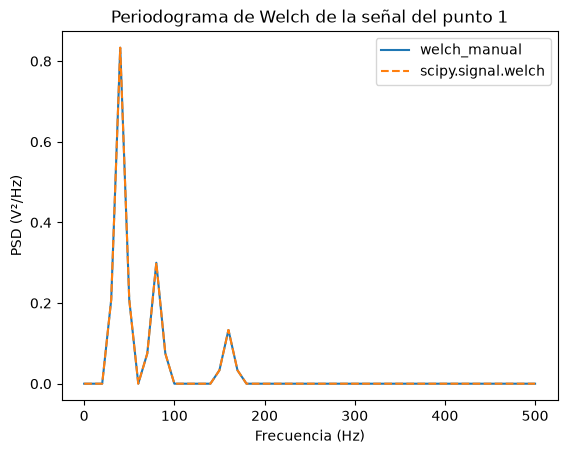

In [11]:
from scipy.signal import welch

L = 100          # largo de cada segmento (resolución Fs/L = 10 Hz)
ov = 50          # solapamiento de 50 %
f_m, psd_m = welch_manual(x, Fs, L, ov)
f_s, psd_s = welch(x, Fs, window="hann", nperseg=L, noverlap=ov, detrend="constant")

print("Máxima diferencia relativa:", np.max(np.abs(psd_m - psd_s))/psd_s.max())

plt.plot(f_m, psd_m, label="welch_manual")
plt.plot(f_s, psd_s, "--", label="scipy.signal.welch")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("PSD (V²/Hz)")
plt.title("Periodograma de Welch de la señal del punto 1")
plt.legend()
plt.show()

**Resultados.** Se probó la función con la señal del punto 1 ($F_s = 1000$ Hz, $N = 250$), usando segmentos de $L = 100$ muestras y 50 % de solapamiento ($K = 4$ segmentos). El periodograma muestra picos en 40, 80 y 160 Hz, con la mayor potencia en 40 Hz, que es la componente de mayor amplitud (5 V). La función creada coincide con `scipy.signal.welch` (diferencia relativa del orden de $10^{-16}$), lo que valida la implementación. Alrededor de cada pico aparecen valores en las frecuencias vecinas (por ejemplo, 30 y 50 Hz): es el efecto de la ventana Hanning, que ensancha los picos.

**6. El archivo adjunto (senecg.mat) contiene una señal de ECG adquirida a una frecuencia de muestreo de 250 Hz. Realice un análisis en frecuencia de la señal usando periodogramas de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que se mostró antes y compruebe que lo haya realizado, calcule la transformada inversa de Fourier de la señal filtrada y compruebe con el periodograma. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventaja) (25%). Compare el método de la librería con la función creada en el punto anterior.**

**Lógica general.** 

(1) Se carga y se grafica la señal. 

(2) Se calcula su periodograma de Welch para ver en qué frecuencias está la potencia. 

(3) Si aparece potencia fuera de la banda útil del ECG, se elimina como en el punto 4: se calcula la DFT, se ponen en cero los coeficientes de la frecuencia de ruido (y sus simétricos) y se aplica la transformada inversa. 

(4) Se comprueba con un nuevo periodograma. 

(5) Se compara `welch_manual` (punto 5) con `scipy.signal.welch`.

['ECG']
Muestras: 1250 | Duración: 5.0 s
Resolución de la DFT completa: Fs/N = 0.2 Hz


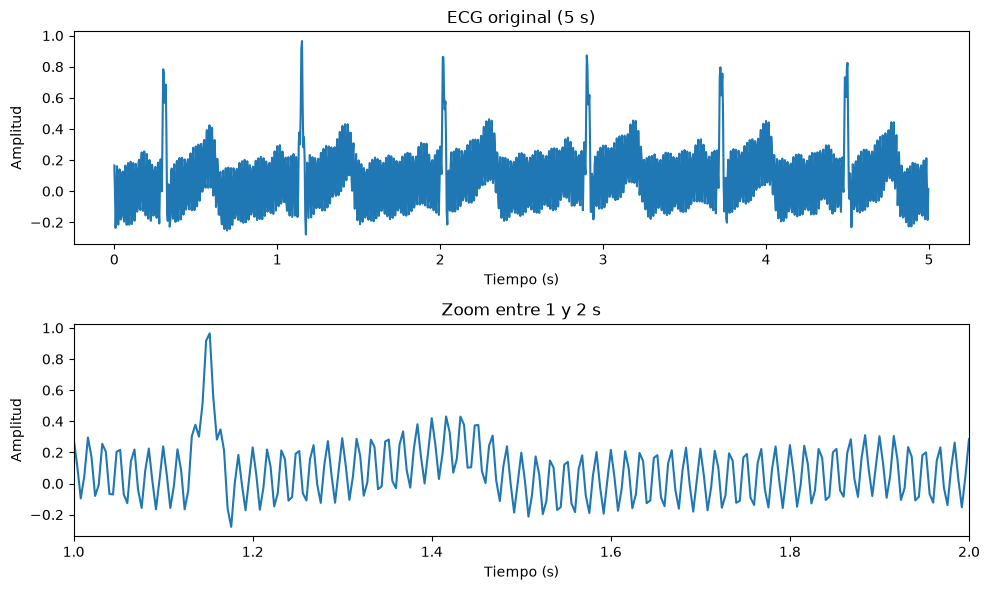

In [12]:
from scipy.io import loadmat

mat = loadmat("senecg.mat")
print([k for k in mat if not k.startswith("__")])   # variables del archivo: ['ECG']

ecg = np.ravel(mat["ECG"]).astype(float)   # (1250, 1) -> vector de 1250 muestras
fs_ecg = 250                               # frecuencia de muestreo (Hz)
N_ecg = len(ecg)
t_ecg = np.arange(N_ecg)/fs_ecg

print("Muestras:", N_ecg, "| Duración:", N_ecg/fs_ecg, "s")
print("Resolución de la DFT completa: Fs/N =", fs_ecg/N_ecg, "Hz")

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(t_ecg, ecg)
ax[0].set(xlabel="Tiempo (s)", ylabel="Amplitud", title="ECG original (5 s)")
ax[1].plot(t_ecg, ecg)
ax[1].set_xlim(1, 2)                       # zoom de 1 s para ver el ruido
ax[1].set(xlabel="Tiempo (s)", ylabel="Amplitud", title="Zoom entre 1 y 2 s")
plt.tight_layout()
plt.show()

**Periodograma de Welch de la señal original.** Se compara el ancho de ventana de 1 s ($L = 250$) con el de 2 s ($L = 500$), ambos con ventana Hanning y 50 % de solapamiento.

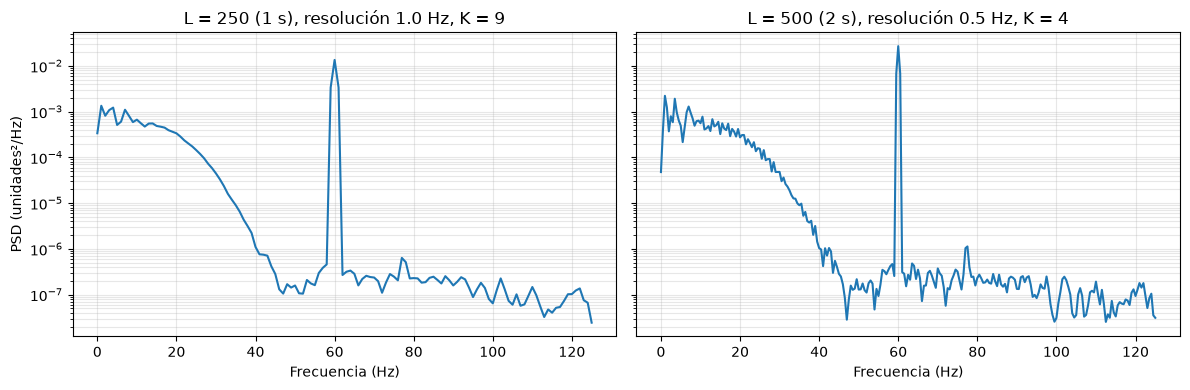

0 - 0.5 Hz (línea base)     :   0.07 % de la potencia
0.5 - 40 Hz (ECG)           :  41.40 % de la potencia
40 - 55 Hz                  :   0.01 % de la potencia
55 - 65 Hz (red eléctrica)  :  58.49 % de la potencia
65 - 125 Hz                 :   0.03 % de la potencia

Frecuencia con mayor potencia: 60.0 Hz


In [14]:
from scipy.signal import welch

def potencia_banda(f, P, f1, f2):
    # Potencia (área bajo la PSD) entre f1 y f2 Hz
    df = f[1] - f[0]
    return np.sum(P[(f >= f1) & (f < f2)])*df

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, L in zip(ax, [250, 500]):
    ov = L//2
    K = (N_ecg - ov)//(L - ov)
    f_w, P_w = welch(ecg, fs_ecg, window="hann", nperseg=L, noverlap=ov)
    a.semilogy(f_w, P_w)
    a.set(xlabel="Frecuencia (Hz)", title=f"L = {L} ({L/fs_ecg:.0f} s), resolución {fs_ecg/L} Hz, K = {K}")
    a.grid(True, which="both", alpha=0.3)
ax[0].set_ylabel("PSD (unidades²/Hz)")
plt.tight_layout()
plt.show()

# Ventana elegida
L_ecg = 500                 # 2 s -> resolución 0.5 Hz
ov_ecg = L_ecg//2           # 50 % de solapamiento
f_o, P_o = welch(ecg, fs_ecg, window="hann", nperseg=L_ecg, noverlap=ov_ecg)

P_total = potencia_banda(f_o, P_o, 0, fs_ecg/2 + 1)
bandas = {"0 - 0.5 Hz (línea base)": (0, 0.5),
        "0.5 - 40 Hz (ECG)": (0.5, 40),
        "40 - 55 Hz": (40, 55),
        "55 - 65 Hz (red eléctrica)": (55, 65),
        "65 - 125 Hz": (65, 126)}
for nombre, (f1, f2) in bandas.items():
    print(f"{nombre:28s}: {100*potencia_banda(f_o, P_o, f1, f2)/P_total:6.2f} % de la potencia")

k60 = np.argmax(P_o)
print("\nFrecuencia con mayor potencia:", f_o[k60], "Hz")

**Elección de la ventana y del solapamiento.**

- **Ancho de la ventana: $L = 500$ muestras (2 s).** La señal solo dura 5 s, así que hay que equilibrar resolución y número de segmentos. Con $L = 500$ la resolución es $F_s/L = 0.5$ Hz, suficiente para separar la frecuencia cardiaca (alrededor de 1.2 Hz, unos 72 lpm) y sus armónicos, y cada segmento contiene al menos dos latidos completos. Con $L = 250$ (1 s) la resolución baja a 1 Hz: los armónicos del latido se juntan y cada segmento tiene apenas un latido. Además, 60 Hz es múltiplo exacto de 0.5 Hz, por lo que el ruido cae justo en un punto de la DFT.

- **Solapamiento: 50 % (250 muestras).** La ventana Hanning atenúa fuertemente los extremos de cada segmento; al solapar la mitad, las muestras que una ventana atenúa quedan en el centro de la siguiente, y no se pierde información. Con 50 % se obtienen $K = (1250 - 250)/(500 - 250) = 4$ segmentos para promediar en lugar de 2 sin solapamiento, lo que reduce la varianza del estimador. Welch mostró que, con ventana Hanning, solapar más del 50 % casi no mejora la varianza y sí aumenta el cálculo (Welch, 1967).

**Diagnóstico del ruido.** El periodograma muestra el contenido típico del ECG entre 0.5 y unos 30 Hz (picos en 1, 3.5 y 7 Hz, armónicos del ritmo cardiaco y energía del QRS) y un **pico aislado y muy angosto en 60 Hz**, que concentra más de la mitad de la potencia total de la señal. Este pico corresponde a **interferencia de la red eléctrica** (en Colombia la red es de 60 Hz) y no tiene origen fisiológico. Sí es necesario eliminarlo. En el zoom temporal se ve como una oscilación rápida montada sobre todo el trazo.

La potencia por debajo de 0.5 Hz (deriva de línea base) es menor al 1 %, y en una señal de solo 5 s la resolución de la DFT (0.2 Hz) no permite separarla bien del contenido del ECG, por lo que no se elimina.

In [15]:
X_ecg = np.fft.fft(ecg)
f_dft = np.fft.fftfreq(N_ecg, d=1/fs_ecg)     

f_ruido = 60          
ancho = 1             
quitar = np.abs(np.abs(f_dft) - f_ruido) <= ancho  

print("Índices eliminados:", np.where(quitar)[0])
print("Frecuencias eliminadas (Hz):", f_dft[quitar])

X_filt = X_ecg.copy()         
X_filt[quitar] = 0

xr_ecg = np.fft.ifft(X_filt)  
print("Parte imaginaria máxima:", abs(xr_ecg.imag).max())
ecg_filt = np.real(xr_ecg)

Índices eliminados: [295 296 297 298 299 300 301 302 303 304 305 945 946 947 948 949 950 951
 952 953 954 955]
Frecuencias eliminadas (Hz): [ 59.   59.2  59.4  59.6  59.8  60.   60.2  60.4  60.6  60.8  61.  -61.
 -60.8 -60.6 -60.4 -60.2 -60.  -59.8 -59.6 -59.4 -59.2 -59. ]
Parte imaginaria máxima: 1.3359448010614673e-16


Como en el punto 4, se construye el espectro filtrado copiando la DFT (arreglo complejo) y poniendo en cero los coeficientes de la banda de ruido. Con $N = 1250$ y $F_s = 250$ Hz, cada índice equivale a $kF_s/N = 0.2k$ Hz, así que 60 Hz corresponde a $k = 300$. Para no dejar la mitad del ruido se elimina también el simétrico $N - k = 950$ (frecuencia $-60$ Hz). Se toma un margen de ±1 Hz (índices 295 a 305 y 945 a 955) por si la frecuencia de la red no es exactamente 60 Hz. La parte imaginaria de la transformada inversa es del orden de $10^{-16}$, lo que confirma que el filtrado respetó la simetría del espectro y la señal resultante es real.

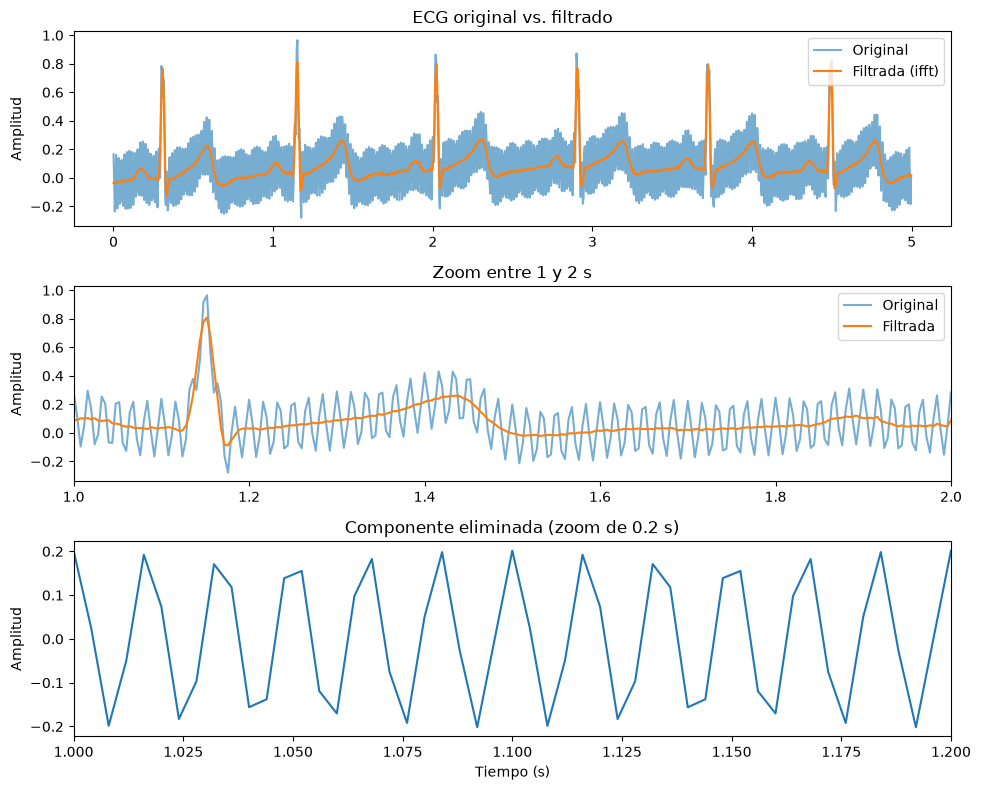

Ruido eliminado: f = 60.0 Hz | amplitud ≈ 0.201 | RMS = 0.142


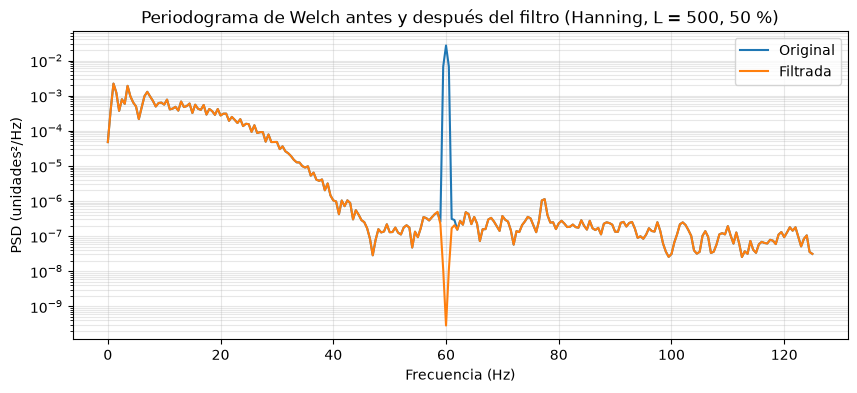

Potencia 55-65 Hz antes:   0.020254474862528824
Potencia 55-65 Hz después: 2.427839438468194e-06
Atenuación en 55-65 Hz: 39.2 dB
Diferencia máx. de PSD en 0.5-40 Hz: 0.00035234668185383275 %


In [16]:
ruido = ecg - ecg_filt          

fig, ax = plt.subplots(3, 1, figsize=(10, 8))
ax[0].plot(t_ecg, ecg, label="Original", alpha=0.6)
ax[0].plot(t_ecg, ecg_filt, label="Filtrada (ifft)")
ax[0].set(ylabel="Amplitud", title="ECG original vs. filtrado")
ax[0].legend(loc="upper right")
ax[1].plot(t_ecg, ecg, label="Original", alpha=0.6)
ax[1].plot(t_ecg, ecg_filt, label="Filtrada")
ax[1].set_xlim(1, 2)
ax[1].set(ylabel="Amplitud", title="Zoom entre 1 y 2 s")
ax[1].legend(loc="upper right")
ax[2].plot(t_ecg, ruido)
ax[2].set_xlim(1, 1.2)
ax[2].set(xlabel="Tiempo (s)", ylabel="Amplitud", title="Componente eliminada (zoom de 0.2 s)")
plt.tight_layout()
plt.show()

k_r = np.argmax(np.abs(np.fft.fft(ruido))[:N_ecg//2])
print("Ruido eliminado: f =", k_r*fs_ecg/N_ecg, "Hz | amplitud ≈",
    round(2*np.abs(X_ecg[k_r])/N_ecg, 3), "| RMS =", round(np.sqrt(np.mean(ruido**2)), 3))

f_f, P_f = welch(ecg_filt, fs_ecg, window="hann", nperseg=L_ecg, noverlap=ov_ecg)

plt.figure(figsize=(10, 4))
plt.semilogy(f_o, P_o, label="Original")
plt.semilogy(f_f, P_f, label="Filtrada")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("PSD (unidades²/Hz)")
plt.title("Periodograma de Welch antes y después del filtro (Hanning, L = 500, 50 %)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

p_antes = potencia_banda(f_o, P_o, 55, 65)
p_desp = potencia_banda(f_f, P_f, 55, 65)
print("Potencia 55-65 Hz antes:  ", p_antes)
print("Potencia 55-65 Hz después:", p_desp)
print("Atenuación en 55-65 Hz:", round(10*np.log10(p_antes/p_desp), 1), "dB")
print("Diferencia máx. de PSD en 0.5-40 Hz:",
    np.max(np.abs(P_o - P_f)[(f_o >= 0.5) & (f_o <= 40)]/P_o[(f_o >= 0.5) & (f_o <= 40)])*100, "%")

**Resultados del filtrado.**

- **En el tiempo:** la señal filtrada conserva la morfología del ECG (onda P, complejo QRS y onda T) sin la oscilación rápida que la cubría. Se observan 6 latidos en 5 s, con intervalos R-R de unos 0.85 s (alrededor de 70 lpm, es decir, ~1.2 Hz, que coincide con el primer pico del periodograma). La componente eliminada es una senoide pura de 60 Hz con amplitud ≈ 0.20 (RMS ≈ 0.14), constante a lo largo de toda la señal, como se espera de la interferencia de red. Los picos R de la señal original se veían más altos (hasta 0.97) porque el ruido se sumaba a ellos; al filtrar quedan alrededor de 0.8.
- **En frecuencia:** el periodograma de la señal filtrada (calculado sobre la transformada inversa) ya no tiene el pico de 60 Hz: la potencia entre 55 y 65 Hz cae de $2.0 \times 10^{-2}$ a $2.4 \times 10^{-6}$, una atenuación de unos 39 dB, y queda al nivel del piso de ruido del resto del espectro. En la banda del ECG (0.5-40 Hz) las dos curvas se superponen (diferencia menor a 0.001 %), es decir, el filtro no alteró el contenido fisiológico.

Esto funciona tan bien porque el ruido es un tono de frecuencia fija que cae exactamente sobre un índice de la DFT ($k = 300$). Este filtro es ideal (corte abrupto); en una señal larga o con ruido de frecuencia variable, poner coeficientes en cero puede generar oscilaciones (efecto Gibbs), y en ese caso es preferible un filtro notch diseñado.

**Comparación de `welch_manual` (punto 5) con `scipy.signal.welch`.** Se usan los mismos parámetros en ambas: ventana Hanning, $L = 500$, 50 % de solapamiento y resta de la media en cada segmento.

Señal original: mismas frecuencias = True | diferencia relativa máx. = 9.6e-17 | tiempo manual = 0.22 ms, scipy = 0.32 ms
Señal filtrada: mismas frecuencias = True | diferencia relativa máx. = 4.9e-16 | tiempo manual = 0.14 ms, scipy = 0.54 ms


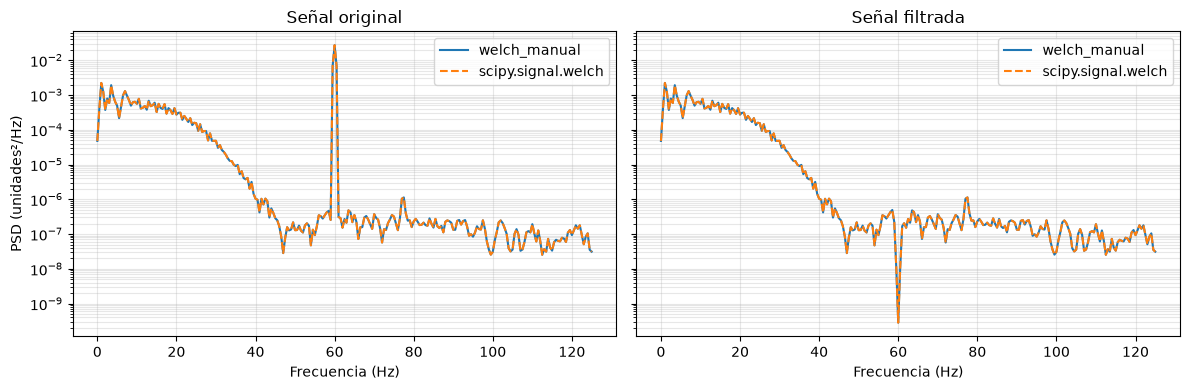

In [17]:
import time

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (nombre, senal) in zip(ax, [("original", ecg), ("filtrada", ecg_filt)]):
    t0 = time.perf_counter()
    for _ in range(200):
        f_m, P_m = welch_manual(senal, fs_ecg, L_ecg, ov_ecg)
    t_man = (time.perf_counter() - t0)/200*1e3

    t0 = time.perf_counter()
    for _ in range(200):
        f_l, P_l = welch(senal, fs_ecg, window="hann", nperseg=L_ecg, noverlap=ov_ecg, detrend="constant")
    t_lib = (time.perf_counter() - t0)/200*1e3

    print(f"Señal {nombre}: mismas frecuencias = {np.allclose(f_m, f_l)} | "
        f"diferencia relativa máx. = {np.max(np.abs(P_m - P_l))/P_l.max():.1e} | "
        f"tiempo manual = {t_man:.2f} ms, scipy = {t_lib:.2f} ms")

    a.semilogy(f_m, P_m, label="welch_manual")
    a.semilogy(f_l, P_l, "--", label="scipy.signal.welch")
    a.set(xlabel="Frecuencia (Hz)", title=f"Señal {nombre}")
    a.grid(True, which="both", alpha=0.3)
    a.legend()
ax[0].set_ylabel("PSD (unidades²/Hz)")
plt.tight_layout()
plt.show()

**Resultados de la comparación.**

 Las dos funciones entregan el mismo eje de frecuencias (0 a 125 Hz cada 0.5 Hz) y la misma PSD, tanto para la señal original como para la filtrada, con diferencias relativas del orden de $10^{-16}$, que es el error numérico del computador. Las curvas se superponen por completo. Esto confirma que `welch_manual` reproduce el algoritmo de la librería: segmentación con solapamiento, resta de la media, ventana Hanning, normalización por $F_s \sum w^2(n)$, espectro de un lado y promedio de los $K = 4$ periodogramas.

En tiempo de cómputo ambas tardan menos de un milisegundo con esta señal (el valor exacto cambia según el computador). La función propia sirve para entender el método, pero `scipy.signal.welch` es la opción recomendable en la práctica: está probada, admite cualquier ventana, distintos tipos de *detrend*, escalado como densidad o como espectro, y trabaja con señales multicanal.

**7. Realice un análisis de frecuencia a través del periodograma de Welch de una señal de EKG de un paciente sano y otra de un paciente con alguna condición cardiaca que en el proyecto 1 hayan identificado que presentaba diferencias, si no encontró diferencias, elija un par al azar. Realice un análisis comparativo de las señales según lo que le indiquen los periodogramas. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventana).**

**Elección de las señales.** En el punto 8 del Proyecto 1, comparado con el ritmo sinusal (SR, paciente sano), el ritmo con mayor diferencia fue la **taquicardia sinusal (ST)**: la frecuencia de máxima potencia (fMP) pasó de una mediana de 3,6 Hz en SR a 5,2 Hz en ST (δ de Cliff = −0,40, efecto mediano), y la suma de frecuencias significativas en bicoherencia (sFSB) de 15 a 12 (δ = 0,52, efecto grande). La fibrilación auricular (AFIB), en cambio, no se diferenció de SR en la fMP (p = 0,47). Por eso se compara un registro SR con uno ST.

De la base Chapman (Zheng *et al.*, 2020) se eligieron dos registros del subconjunto del proyecto (40 a 79 años) con la **misma edad y el mismo sexo** (mujeres de 61 años), para que esas variables no confundan la comparación, sin otras alteraciones del ECG (`Beat = NONE`) y con frecuencia cardiaca cercana a la mediana de su ritmo en el subconjunto (74 lpm en SR y 108 lpm en ST). Como en el proyecto, se usa la derivación II (columna 1), registrada a 500 Hz durante 10 s. Las señales de `ECGDataDenoised` ya vienen filtradas por los autores de la base, por lo que aquí no se elimina ruido.

**Lógica general.** 

(1) Se cargan y grafican las dos señales y se mide la frecuencia cardiaca a partir de los picos R. 

(2) Se elige el ancho de la ventana comparando varias opciones. 

(3) Se calcula el periodograma de Welch de cada señal y se extraen características: frecuencia fundamental, frecuencia de máxima potencia, centroide espectral y potencia por bandas. 

(4) Se comparan entre sí y con los resultados del Proyecto 1.

,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration
7379,MUSE_20180209_113846_75000,SR,NONE,61,FEMALE,73,73,58
8659,MUSE_20180112_072629_46000,ST,NONE,61,FEMALE,105,105,78


SR: 5000 muestras (10 s) | 12 latidos | RR medio = 0.820 s | FC = 73.2 lpm | desv. RR = 7.0 ms
ST: 5000 muestras (10 s) | 17 latidos | RR medio = 0.574 s | FC = 104.6 lpm | desv. RR = 2.9 ms


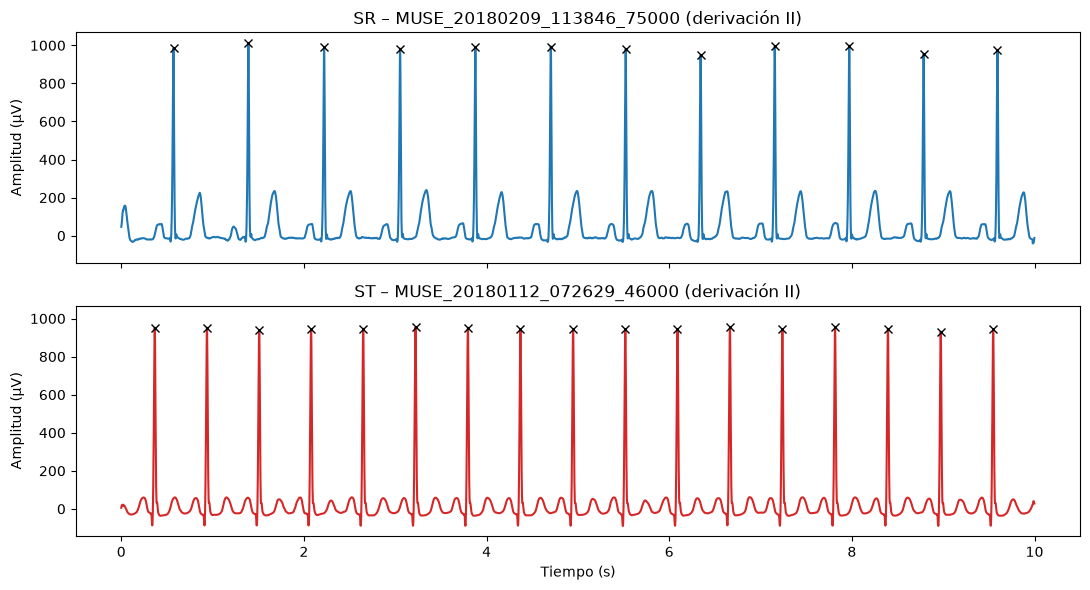

In [ ]:
import pandas as pd
from pathlib import Path
from scipy.signal import find_peaks

SIGNALS_DIR = Path(".")   
FS_CH = 500        
LEAD_II = 1        

registros = {"SR": "MUSE_20180209_113846_75000",    
            "ST": "MUSE_20180112_072629_46000"}    

diag = pd.read_excel("Diagnostics.xlsx")
display(diag[diag["FileName"].isin(registros.values())]
        [["FileName", "Rhythm", "Beat", "PatientAge", "Gender", "VentricularRate", "AtrialRate", "QRSDuration"]])

ecg_ch, picos_R = {}, {}
for ritmo, archivo in registros.items():
    x_ch = pd.read_csv(SIGNALS_DIR / f"{archivo}.csv", header=None).iloc[:, LEAD_II].to_numpy(float)
    ecg_ch[ritmo] = x_ch
    
    r, _ = find_peaks(x_ch, height=0.5*x_ch.max(), distance=int(0.3*FS_CH))
    picos_R[ritmo] = r
    rr = np.diff(r)/FS_CH
    print(f"{ritmo}: {len(x_ch)} muestras ({len(x_ch)/FS_CH:.0f} s) | {len(r)} latidos | "
        f"RR medio = {rr.mean():.3f} s | FC = {60/rr.mean():.1f} lpm | desv. RR = {1000*rr.std():.1f} ms")

t_ch = np.arange(len(ecg_ch["SR"]))/FS_CH
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
for a, (ritmo, color) in zip(ax, [("SR", "tab:blue"), ("ST", "tab:red")]):
    a.plot(t_ch, ecg_ch[ritmo], color=color)
    a.plot(picos_R[ritmo]/FS_CH, ecg_ch[ritmo][picos_R[ritmo]], "kx")
    a.set(ylabel="Amplitud (µV)", title=f"{ritmo} – {registros[ritmo]} (derivación II)")
ax[1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

**Las señales en el tiempo.** El registro SR tiene 12 latidos en 10 s (RR medio de 0,82 s, **73 lpm**) y el ST tiene 17 (RR de 0,57 s, **105 lpm**). Estos valores coinciden con la frecuencia ventricular de `Diagnostics.xlsx` (73 y 105 lpm). En ambos registros cada QRS va precedido de una onda P, como corresponde a un ritmo de origen sinusal, y los picos R tienen amplitud parecida (~950-1000 µV). Las diferencias son que en ST los latidos están más juntos, el tramo entre la onda T y la siguiente onda P casi desaparece, y la onda T es mucho más baja (~60 µV frente a ~230 µV en SR). Los dos ritmos son regulares (desviación de los RR menor a 10 ms).

**Elección del ancho de la ventana.** Se compara el periodograma con ventanas de 2, 4 y 5 s, todas Hanning con 50 % de solapamiento.

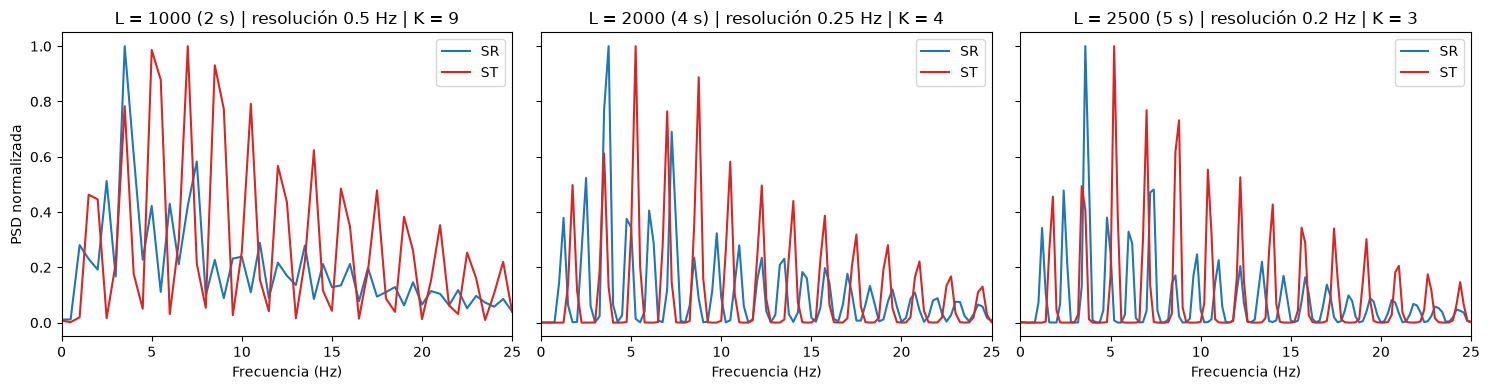

In [20]:
from scipy.signal import welch

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, L in zip(ax, [1000, 2000, 2500]):
    ov = L//2
    K = (len(ecg_ch["SR"]) - ov)//(L - ov)
    for ritmo, color in [("SR", "tab:blue"), ("ST", "tab:red")]:
        f_w, P_w = welch(ecg_ch[ritmo], FS_CH, window="hann", nperseg=L, noverlap=ov)
        a.plot(f_w, P_w/P_w.max(), color=color, label=ritmo)
    a.set(xlim=(0, 25), xlabel="Frecuencia (Hz)",
        title=f"L = {L} ({L/FS_CH:.0f} s) | resolución {FS_CH/L} Hz | K = {K}")
    a.legend()
ax[0].set_ylabel("PSD normalizada")
plt.tight_layout()
plt.show()

**Justificación de la ventana y del solapamiento.**

- **Ancho de la ventana: $L = 2000$ muestras (4 s).** El espectro de un ritmo regular está formado por la frecuencia cardiaca $f_0$ y sus armónicos ($2f_0$, $3f_0$, …), separados entre sí por $f_0$: 1,2 Hz en SR y 1,75 Hz en ST. Para compararlos hay que poder separar esos armónicos, por lo que la resolución $F_s/L$ debe ser bastante menor que 1,2 Hz. Con $L = 1000$ (2 s, la misma duración del punto 6) la resolución es 0,5 Hz y los armónicos de SR quedan separados por menos de 3 puntos, así que se mezclan (en la gráfica de la izquierda los picos de SR no siguen una serie clara). Con $L = 2000$ la resolución es 0,25 Hz, los armónicos de los dos ritmos se separan bien (los de SR quedan cada ~5 puntos) y cada segmento contiene entre 4 y 7 latidos. Con $L = 2500$ (5 s) la resolución mejora poco, pero solo quedan 3 segmentos para promediar y la estimación es más ruidosa.
- **Solapamiento: 50 % (1000 muestras).** Por el mismo argumento del punto 6: la ventana Hanning atenúa los extremos de cada segmento y, al solapar la mitad, esas muestras quedan en el centro del segmento siguiente. Con 50 % hay $K = (5000 - 1000)/(2000 - 1000) = 4$ segmentos en lugar de 2 sin solapamiento, y solapar más casi no reduce la varianza con esta ventana (Welch, 1967).

En el punto 6 se usaron 2 s porque esa señal solo duraba 5 s; aquí los registros duran 10 s y se puede usar una ventana más larga sin quedarse con muy pocos segmentos.

,SR,ST
FC picos R (Hz),1.22,1.74
f0 en Welch (Hz),1.25,1.75
"fMP 0,3-20 Hz (Hz)",3.75,5.25
fMP / f0 (armónico),3.08,3.01
"Centroide 0,5-40 Hz (Hz)",10.73,12.02
"% potencia 0,5-5 Hz",31.40,13.80
% potencia 5-15 Hz,42.60,54.90
% potencia 15-40 Hz,26.00,31.30
Potencia total (µV²),18620.00,22108.00


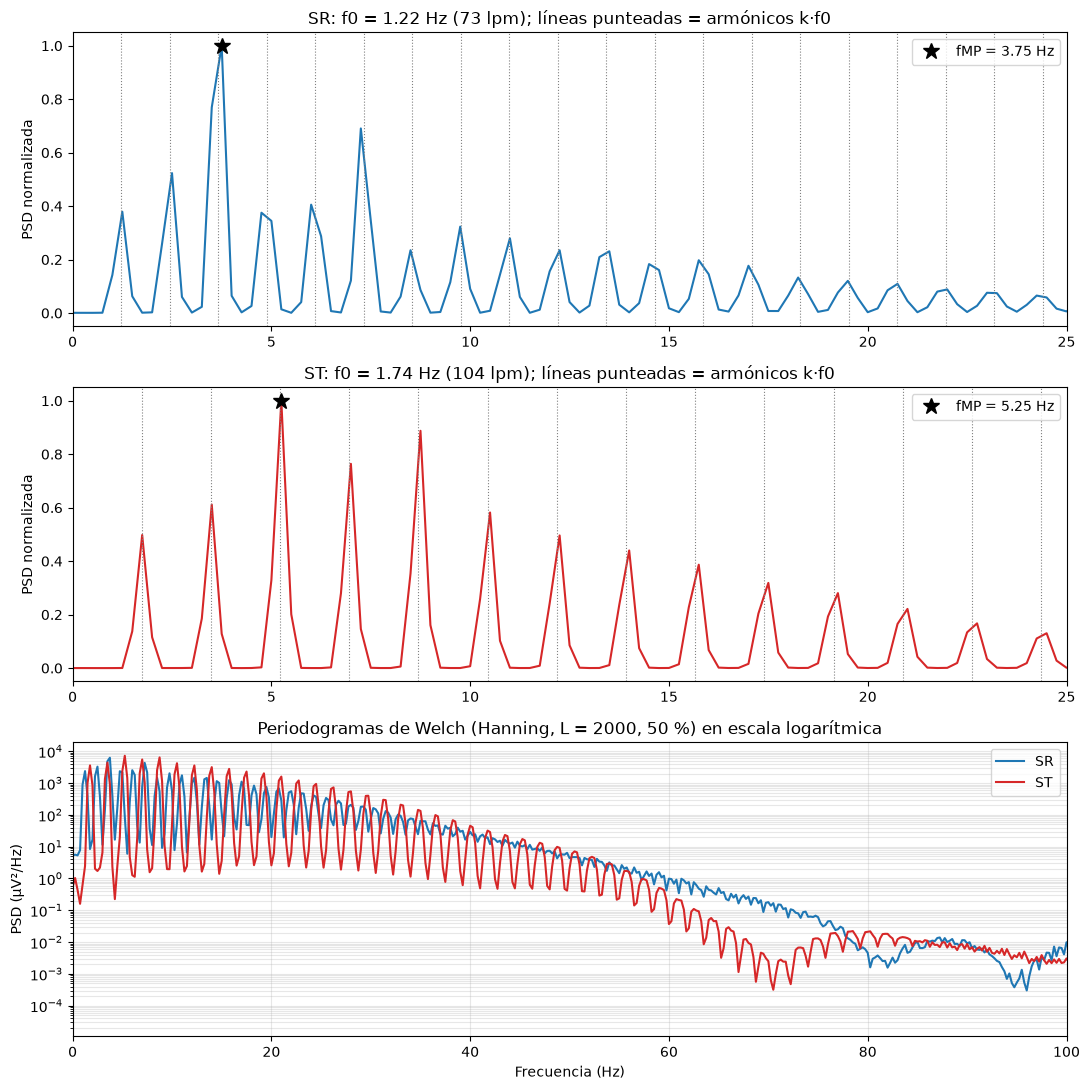

In [21]:
L_ch = 2000              
ov_ch = L_ch//2          

def caracteristicas_welch(f, P, fc):
    
    banda = (f >= 0.5) & (f <= 40)
    zona_fmp = (f >= 0.3) & (f <= 20)          
    fmp = f[zona_fmp][np.argmax(P[zona_fmp])]
    cerca = np.abs(f - fc) <= 0.3              
    return {"FC picos R (Hz)": round(fc, 2),
            "f0 en Welch (Hz)": f[cerca][np.argmax(P[cerca])],
            "fMP 0,3-20 Hz (Hz)": fmp,
            "fMP / f0 (armónico)": round(fmp/fc, 2),
            "Centroide 0,5-40 Hz (Hz)": round(np.sum(f[banda]*P[banda])/np.sum(P[banda]), 2),
            "% potencia 0,5-5 Hz": round(100*potencia_banda(f, P, 0.5, 5)/potencia_banda(f, P, 0.5, 40), 1),
            "% potencia 5-15 Hz": round(100*potencia_banda(f, P, 5, 15)/potencia_banda(f, P, 0.5, 40), 1),
            "% potencia 15-40 Hz": round(100*potencia_banda(f, P, 15, 40)/potencia_banda(f, P, 0.5, 40), 1),
            "Potencia total (µV²)": round(potencia_banda(f, P, 0, FS_CH/2 + 1))}

psd_ch, tabla = {}, {}
for ritmo in ["SR", "ST"]:
    f_c, P_c = welch(ecg_ch[ritmo], FS_CH, window="hann", nperseg=L_ch, noverlap=ov_ch)
    psd_ch[ritmo] = (f_c, P_c)
    fc = 60/np.mean(np.diff(picos_R[ritmo])/FS_CH)/60
    tabla[ritmo] = caracteristicas_welch(f_c, P_c, fc)

tabla = pd.DataFrame(tabla)
display(tabla)

fig, ax = plt.subplots(3, 1, figsize=(11, 11))
for i, (ritmo, color) in enumerate([("SR", "tab:blue"), ("ST", "tab:red")]):
    f_c, P_c = psd_ch[ritmo]
    f0 = tabla.loc["FC picos R (Hz)", ritmo]
    ax[i].plot(f_c, P_c/P_c.max(), color=color)
    for k in range(1, int(25/f0) + 1):                     # armónicos k·f0
        ax[i].axvline(k*f0, color="gray", ls=":", lw=0.8)
    fmp = tabla.loc["fMP 0,3-20 Hz (Hz)", ritmo]
    ax[i].plot(fmp, 1, "k*", ms=12, label=f"fMP = {fmp} Hz")
    ax[i].set(xlim=(0, 25), ylabel="PSD normalizada",
            title=f"{ritmo}: f0 = {f0} Hz ({60*f0:.0f} lpm); líneas punteadas = armónicos k·f0")
    ax[i].legend(loc="upper right")
for ritmo, color in [("SR", "tab:blue"), ("ST", "tab:red")]:
    ax[2].semilogy(*psd_ch[ritmo], color=color, label=ritmo)
ax[2].set(xlim=(0, 100), xlabel="Frecuencia (Hz)", ylabel="PSD (µV²/Hz)",
        title="Periodogramas de Welch (Hanning, L = 2000, 50 %) en escala logarítmica")
ax[2].grid(True, which="both", alpha=0.3)
ax[2].legend()
plt.tight_layout()
plt.show()

**Análisis comparativo de los periodogramas.**

1. **Estructura armónica.** Los dos periodogramas están formados por picos angostos y equiespaciados, con valles casi en cero entre ellos (líneas punteadas). Es el espectro típico de una señal periódica: la frecuencia fundamental $f_0$ coincide con la frecuencia cardiaca medida con los picos R (1,25 Hz en SR y 1,75 Hz en ST en el periodograma, frente a 1,22 y 1,74 Hz medidos en el tiempo; la diferencia es menor que la resolución de 0,25 Hz). Que los picos sean tan definidos indica que **los dos ritmos son regulares**. En un ritmo irregular, como la AFIB, la frecuencia del latido cambia de un latido a otro y los armónicos se ensanchan y se mezclan.
2. **Desplazamiento hacia frecuencias altas en ST.** Como el corazón late 1,43 veces más rápido en ST (104,6 frente a 73,2 lpm), todos los armónicos se separan en esa misma proporción: entre 0 y 25 Hz hay unos 20 armónicos en SR y solo 14 en ST. La frecuencia de máxima potencia pasa de **3,75 Hz en SR a 5,25 Hz en ST**, y en ambos casos corresponde al **tercer armónico** de la frecuencia cardiaca (fMP/f₀ = 3,08 y 3,01).
3. **Distribución de la potencia.** En SR el 31 % de la potencia entre 0,5 y 40 Hz está por debajo de 5 Hz, frente a solo el 14 % en ST. En ST la potencia se concentra entre 5 y 15 Hz (55 % frente a 43 %), y el centroide espectral sube de 10,7 a 12,0 Hz. Esto se explica por dos razones: el desplazamiento de los armónicos descrito en el punto anterior, y la onda T, que es una onda lenta (contenido por debajo de ~5 Hz) y en este registro SR es casi 4 veces más alta que en el ST.
4. **Frecuencias por encima de 40 Hz.** En la escala logarítmica, el periodograma de SR cae más lento que el de ST entre 40 y 80 Hz, aunque esta banda aporta menos del 1 % de la potencia en ambos. Coincide con que el QRS de este registro SR es más angosto (58 ms frente a 78 ms en ST, según `Diagnostics.xlsx`): un pulso más angosto tiene flancos más rápidos y por eso más contenido en frecuencias altas.
5. **Potencia total.** Es del mismo orden en los dos registros (18 620 y 22 108 µV²), porque los picos R tienen amplitud parecida. La diferencia entre los ritmos está en **cómo se reparte** la potencia en frecuencia, no en cuánta potencia hay.

**Relación con el Proyecto 1.** Los valores de fMP de este par coinciden con lo encontrado en el proyecto para todo el subconjunto: 3,75 Hz en SR (mediana del proyecto: 3,6 Hz, RIC 2,6-4,6) y 5,25 Hz en ST (mediana: 5,2 Hz, RIC 3,5-6,4). El periodograma ayuda a explicar por qué: **la fMP no es una frecuencia propia de la arritmia, sino un armónico de la frecuencia cardiaca** (aquí el tercero en ambos casos), por lo que la diferencia de fMP entre SR y ST refleja sobre todo que ST es más rápido. Esto confirma la limitación que se señaló en el proyecto: la frecuencia cardiaca actúa como variable de confusión en la fMP.

**Limitaciones.** Se comparó un solo par de registros, así que estos resultados describen a estas dos pacientes y no permiten generalizar; las diferencias poblacionales son las del Proyecto 1. En particular, la diferencia en la altura de la onda T puede ser propia de estas pacientes y no de la taquicardia sinusal. Además, con 10 s de señal solo hay 4 segmentos para promediar, por lo que la estimación de la PSD tiene una varianza apreciable.

**Verificación con `welch_manual`.** Se repite el cálculo con la función del punto 5.

In [22]:
# Verificación con la función del punto 5
for ritmo in ["SR", "ST"]:
    f_m7, P_m7 = welch_manual(ecg_ch[ritmo], FS_CH, L_ch, ov_ch)
    f_c, P_c = psd_ch[ritmo]
    print(f"{ritmo}: diferencia relativa máx. welch_manual vs scipy = {np.max(np.abs(P_m7 - P_c))/P_c.max():.1e}")

SR: diferencia relativa máx. welch_manual vs scipy = 5.8e-16
ST: diferencia relativa máx. welch_manual vs scipy = 5.0e-16


---

**8. Conclusiones y referencias**

**Conclusiones**

- **Muestreo y representación (parte guiada y punto 1).** Una señal muestreada puede verse en función del tiempo ($t = nT$) o del número de muestra, con frecuencia discreta $f = F/F_s$; es la misma señal con distinto eje. Para representar la suma de senoides de 40, 80 y 160 Hz, el criterio de Nyquist exige $F_s > 320$ Hz; con $F_s = 1000$ Hz la forma de onda se representa bien. La potencia de una señal periódica no depende de cuántos ciclos se tomen (12,5 W en 1 y en 10 ciclos), mientras que la energía sí crece con la duración.
- **DFT e inversa (puntos 2 y 3).** La DFT identificó las tres componentes (40, 80 y 160 Hz) y permitió recuperar sus amplitudes con $A = 2|X(k)|/N$. Trabajar con un número entero de periodos hizo que cada componente cayera exactamente en un índice de la DFT, sin fuga espectral. La transformada inversa (`np.fft.ifft`) recuperó la señal con un error del orden de $10^{-15}$, es decir, el par DFT/IDFT no pierde información.
- **Filtrado en frecuencia (puntos 4 y 6).** Poner en cero coeficientes de la DFT y aplicar la inversa es un filtro ideal. Para que funcione, el arreglo debe ser complejo y hay que eliminar también el coeficiente simétrico $N-k$; si no, se pierde la fase o se recupera solo la mitad de la amplitud. Aplicado al ECG de `senecg.mat`, eliminó la interferencia de red de 60 Hz, que concentraba el 58 % de la potencia, con una atenuación de unos 39 dB y sin alterar la banda del ECG (0,5-40 Hz). Funcionó tan bien porque el ruido era un tono de frecuencia fija sobre un índice exacto de la DFT; con ruido de frecuencia variable sería preferible un filtro diseñado.
- **Periodograma de Welch (puntos 5 a 7).** La función propia `welch_manual` reprodujo `scipy.signal.welch` con diferencias del orden de $10^{-16}$ en todas las señales probadas. La elección de la ventana es un compromiso entre resolución en frecuencia ($F_s/L$) y número de segmentos que se promedian (varianza): en el ECG de 5 s se usaron 2 s y en los registros de 10 s, 4 s, para separar los armónicos de la frecuencia cardiaca sin quedarse con muy pocos segmentos. El solapamiento del 50 % aprovecha las muestras que la ventana Hanning atenúa en los extremos.
- **SR frente a ST (punto 7).** Los periodogramas de los dos ritmos son series de armónicos de la frecuencia cardiaca. En ST todo el espectro se desplaza hacia frecuencias más altas en proporción a la frecuencia cardiaca: la frecuencia de máxima potencia pasó de 3,75 a 5,25 Hz, en ambos casos el tercer armónico, y la potencia se concentró entre 5 y 15 Hz. Estos valores coinciden con las medianas del Proyecto 1 (3,6 y 5,2 Hz) y muestran que la diferencia de fMP entre estos ritmos se explica principalmente por la frecuencia cardiaca.
- **En general,** el análisis en frecuencia permitió detectar y eliminar ruido que en el tiempo cubría la señal, y describir los ritmos cardiacos por cómo reparten su potencia. Su interpretación exige tener presentes la resolución, la ventana y la duración del registro.

**Referencias**

- Harris, C. R., Millman, K. J., van der Walt, S. J., *et al.* (2020). Array programming with NumPy. *Nature*, 585, 357-362. https://doi.org/10.1038/s41586-020-2649-2
- Proakis, J. G., y Manolakis, D. G. (2007). *Digital Signal Processing: Principles, Algorithms, and Applications* (4.ª ed.). Prentice Hall.
- Virtanen, P., Gommers, R., Oliphant, T. E., *et al.* (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261-272. https://doi.org/10.1038/s41592-019-0686-2
- Welch, P. D. (1967). The use of fast Fourier transform for the estimation of power spectra: A method based on time averaging over short, modified periodograms. *IEEE Transactions on Audio and Electroacoustics*, 15(2), 70-73. https://doi.org/10.1109/TAU.1967.1161901
- Zheng, J., Zhang, J., Danioko, S., Yao, H., Guo, H., y Rakovski, C. (2020). A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients. *Scientific Data*, 7, 48. https://doi.org/10.1038/s41597-020-0386-x